# 20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed: tuned



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "tuned" / "by_family" / '20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.461166,0.054579,15
1,DAGMA_Linear,0.307111,0.086344,15
2,DAGMA_Nonlinear,0.303050,0.094128,15
3,DAS,0.306335,0.091826,15
4,DirectLiNGAM,0.356253,0.117663,15
5,FCI,0.216117,0.057996,15
6,GES,0.473940,0.154657,15
7,GOLEM,0.382402,0.128244,15
8,GRaSP,0.586703,0.088685,15
9,GraNDAG,0.193950,0.167643,15


,model,mean,std,size
0,AVICI,43.000000,5.385165,15
1,DAGMA_Linear,50.533333,8.782016,15
2,DAGMA_Nonlinear,51.133333,10.044947,15
3,DAS,66.600000,15.324117,15
4,DirectLiNGAM,53.266667,13.040961,15
5,FCI,47.306667,6.845589,15
6,GES,46.266667,16.537691,15
7,GOLEM,47.866667,10.575353,15
8,GRaSP,37.760000,9.729249,15
9,GraNDAG,51.666667,8.949594,15


,model,mean,std,size
0,AVICI,0.768939,0.075227,15
1,DAGMA_Linear,0.444381,0.112807,15
2,DAGMA_Nonlinear,0.566424,0.187548,15
3,DAS,0.301984,0.103117,15
4,DirectLiNGAM,0.432386,0.163679,15
5,FCI,0.822566,0.105243,15
6,GES,0.591641,0.215169,15
7,GOLEM,0.534772,0.180010,15
8,GRaSP,0.716847,0.120267,15
9,GraNDAG,0.612194,0.296770,15


,model,mean,std,size
0,AVICI,0.333072,0.056731,15
1,DAGMA_Linear,0.236218,0.072825,15
2,DAGMA_Nonlinear,0.210223,0.065584,15
3,DAS,0.313954,0.084183,15
4,DirectLiNGAM,0.307633,0.099933,15
5,FCI,0.126688,0.036706,15
6,GES,0.401357,0.129308,15
7,GOLEM,0.299591,0.102998,15
8,GRaSP,0.502389,0.087512,15
9,GraNDAG,0.128797,0.125369,15


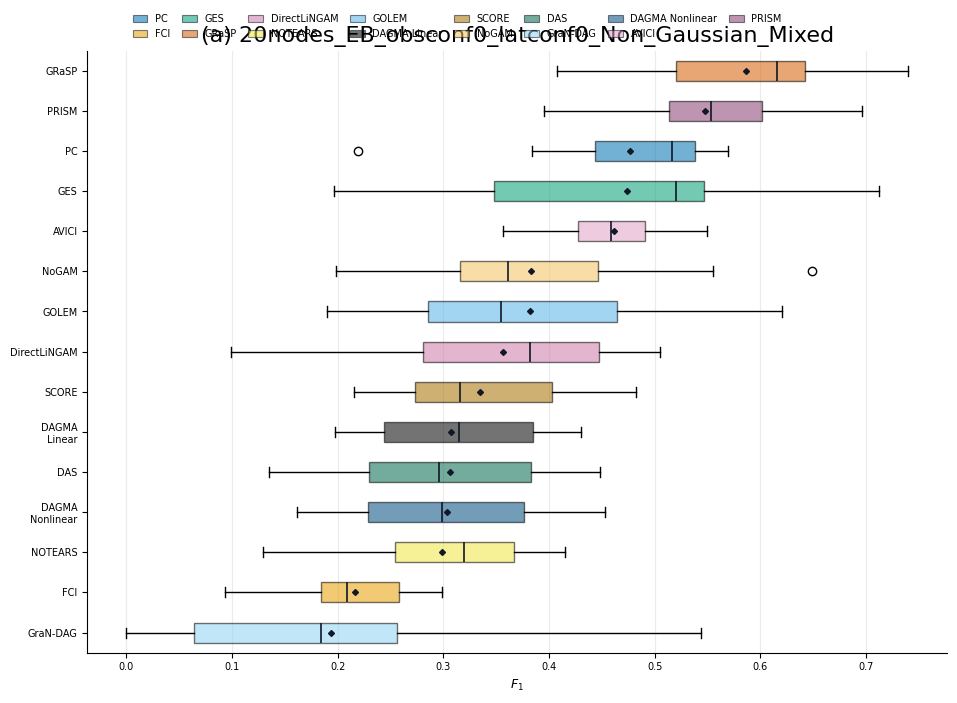

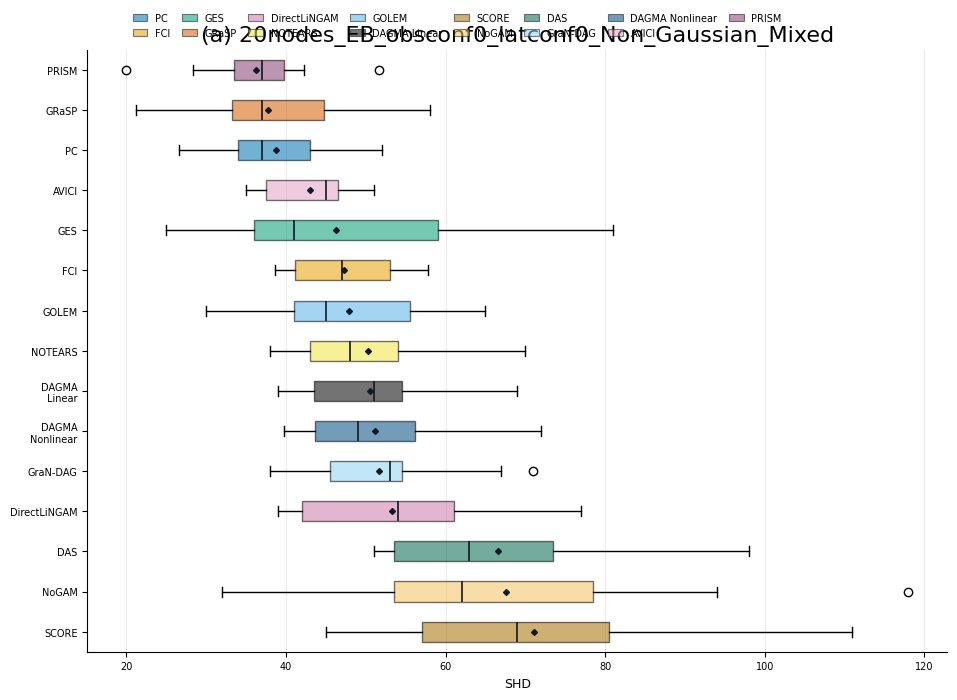

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.082813
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.238806
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.170213
9,19,GraNDAG,0.000000


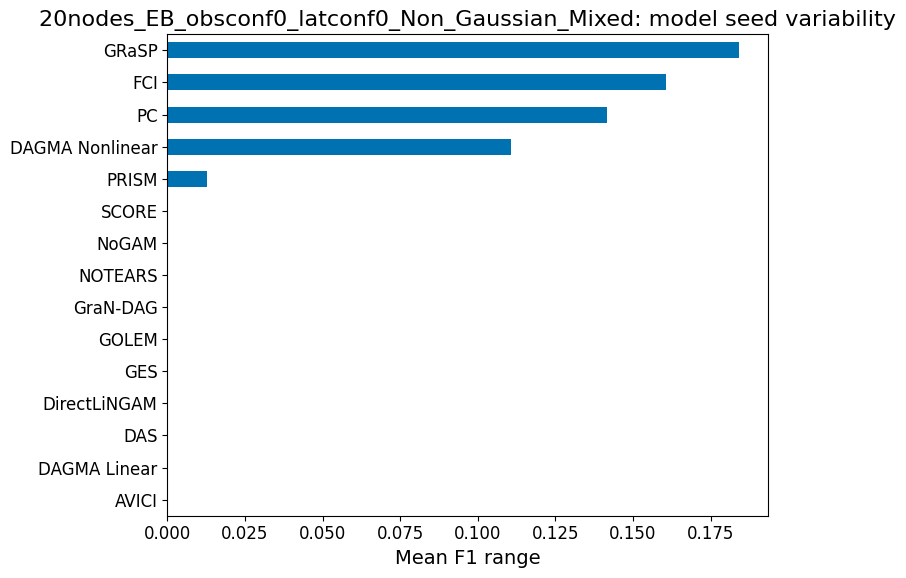

,model_seed,model,f1_range
0,0,AVICI,0.193836
1,0,DAGMA_Linear,0.232849
2,0,DAGMA_Nonlinear,0.388564
3,0,DAS,0.313141
4,0,DirectLiNGAM,0.406253
5,0,FCI,0.282737
6,0,GES,0.516793
7,0,GOLEM,0.431216
8,0,GRaSP,0.258382
9,0,GraNDAG,0.543689


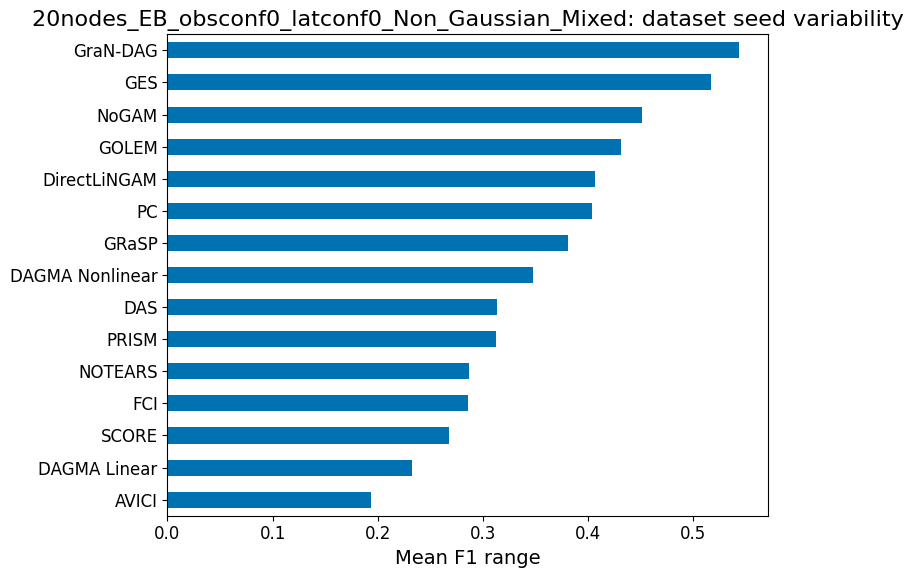

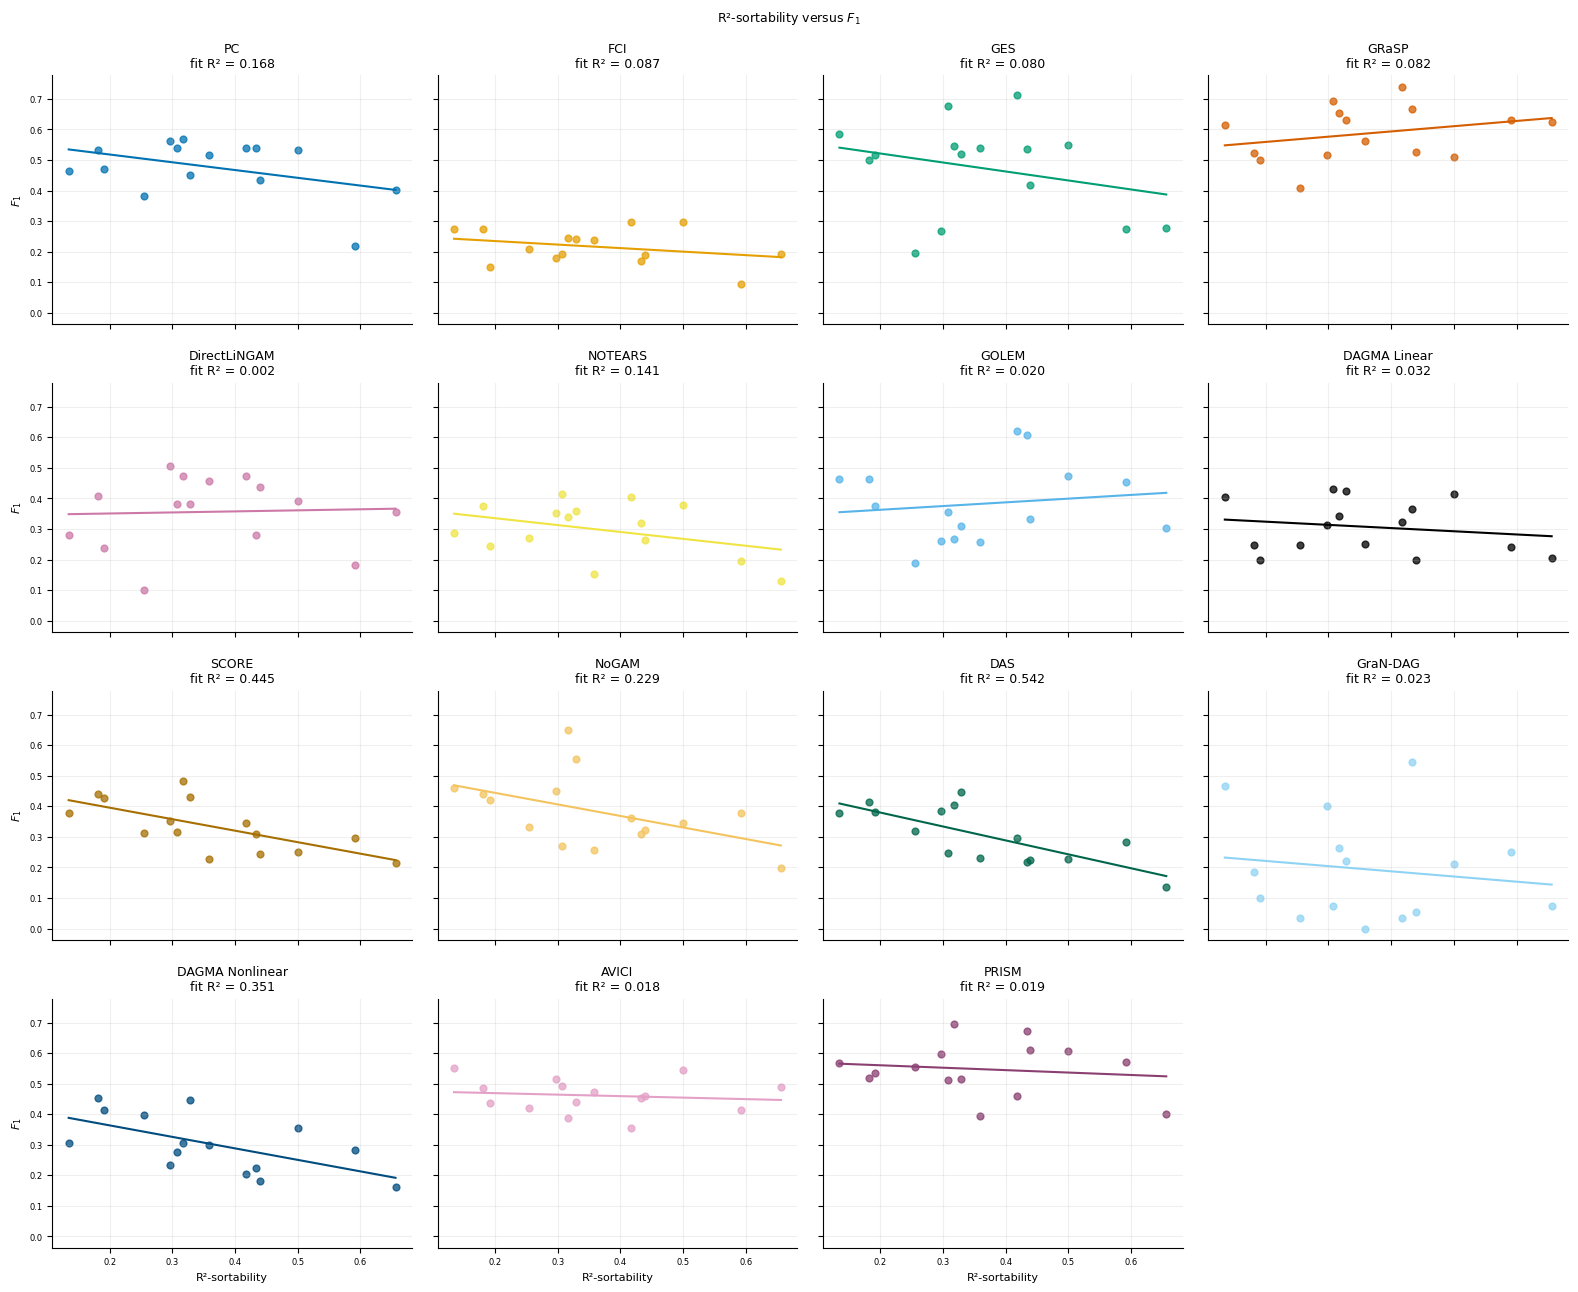

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,0.414634,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,0.240964,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,0.283167,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,0.283333,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,0.181818,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,0.092841,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,0.272727,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,0.454545,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,0.629787,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,0.250000,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.494340,0.358491,265,131,0,95,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.742015,0.656020,407,302,0,267,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.679688,0.433594,256,174,0,111,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.317992,0.297071,239,76,0,71,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.521246,0.328612,353,184,0,116,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.313589,0.181185,287,90,0,52,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.374517,0.254826,259,97,0,66,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.703448,0.317241,145,102,0,46,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.492228,0.134715,193,95,0,26,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,-0.132785,0.017632,-0.048883,0.478795,0.637101,-0.150000,0.593630
1,DAGMA_Linear,15,-0.179471,0.032210,-0.104525,0.344805,0.522162,-0.110714,0.694463
2,DAGMA_Nonlinear,15,-0.592822,0.351438,-0.376388,0.438785,0.019855,-0.610714,0.015593
3,DAS,15,-0.736156,0.541926,-0.455962,0.470766,0.001753,-0.707143,0.003195
4,DirectLiNGAM,15,0.043248,0.001870,0.034324,0.343875,0.878368,0.060714,0.829812
5,FCI,15,-0.294756,0.086881,-0.115306,0.257699,0.286210,-0.167857,0.549856
6,GES,15,-0.282024,0.079538,-0.294203,0.580037,0.308496,-0.064286,0.819948
7,GOLEM,15,0.140637,0.019779,0.121655,0.338530,0.617125,0.121429,0.666401
8,GRaSP,15,0.286859,0.082288,0.171597,0.524821,0.299918,0.307143,0.265473
9,GraNDAG,15,-0.150071,0.022521,-0.169697,0.255147,0.593453,-0.135714,0.629620


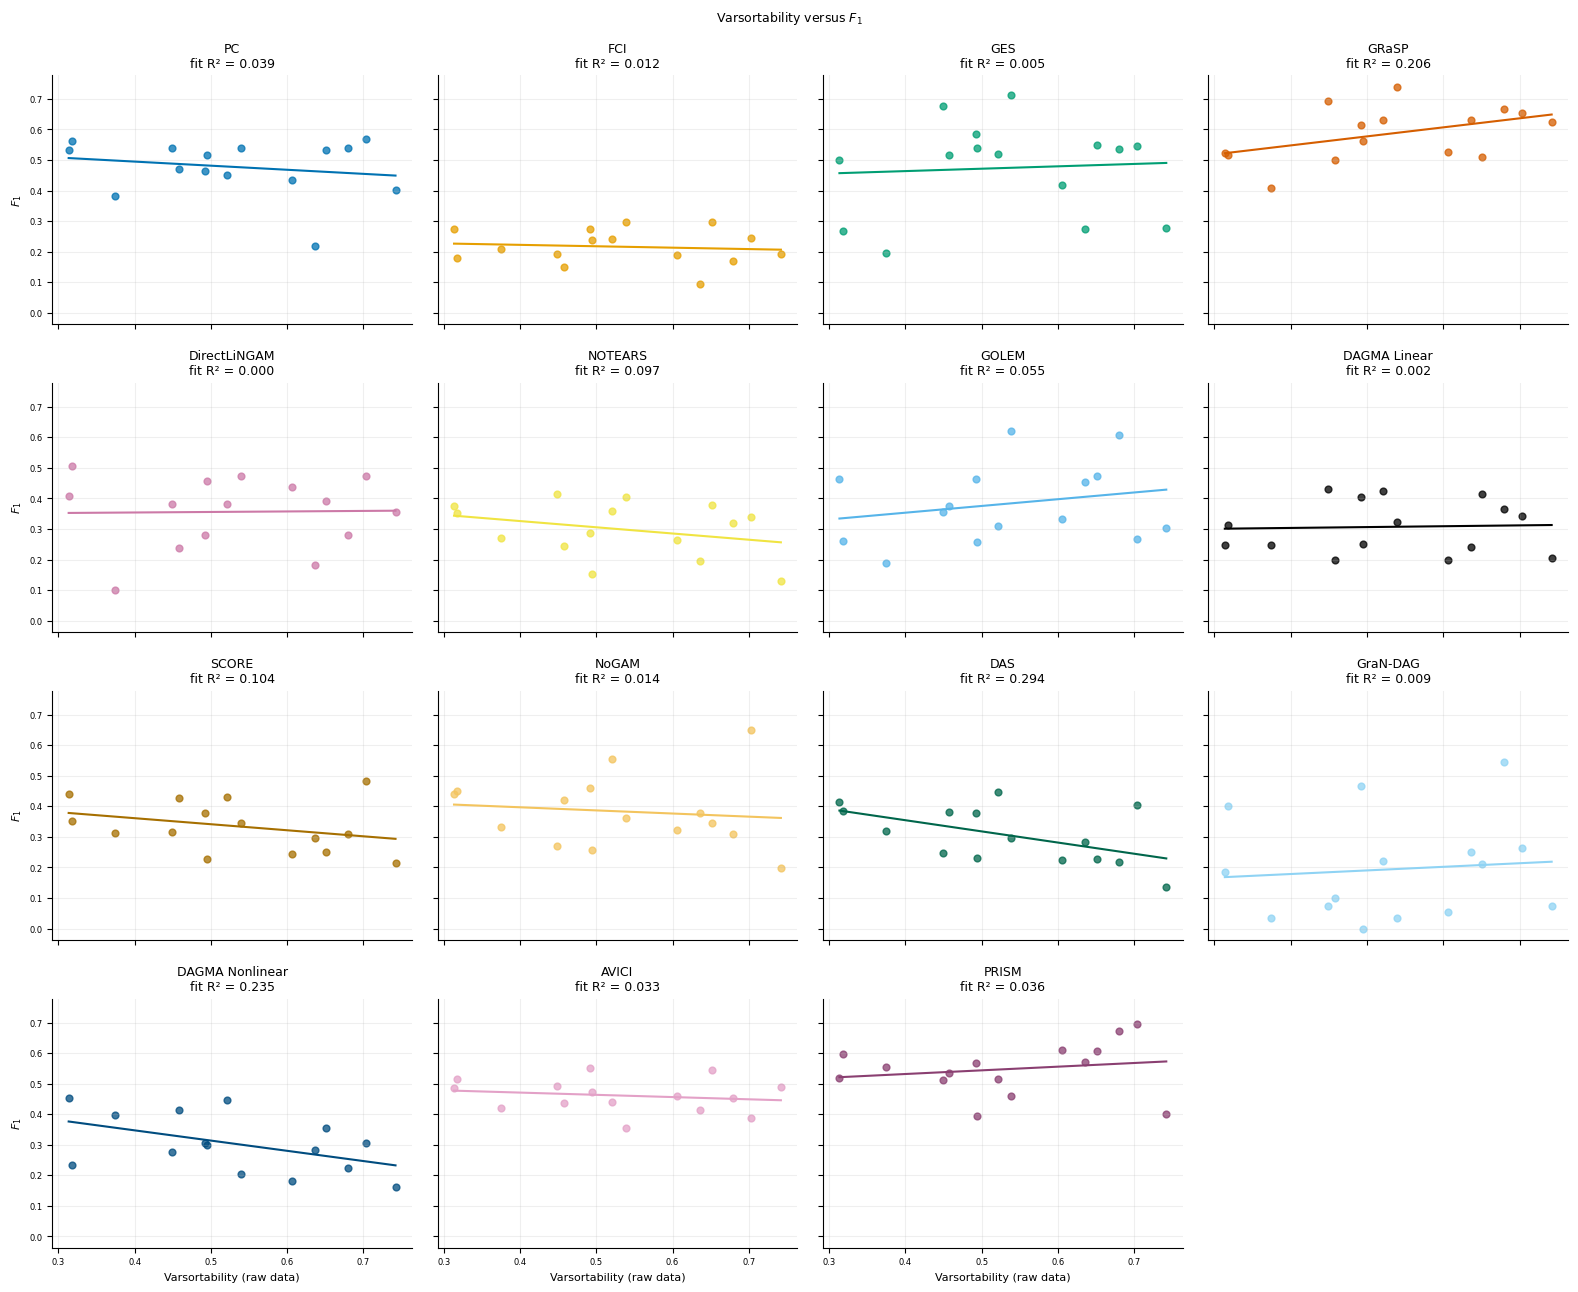

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,0.414634,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,0.240964,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,0.283167,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,0.283333,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,0.181818,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,0.092841,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,0.272727,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,0.454545,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,0.629787,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,0.250000,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.494340,0.358491,265,131,0,95,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.742015,0.656020,407,302,0,267,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.679688,0.433594,256,174,0,111,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.317992,0.297071,239,76,0,71,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.521246,0.328612,353,184,0,116,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.313589,0.181185,287,90,0,52,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.374517,0.254826,259,97,0,66,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.703448,0.317241,145,102,0,46,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.492228,0.134715,193,95,0,26,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,-0.182923,0.033461,-0.073304,0.500152,0.514054,-0.228571,0.412566
1,DAGMA_Linear,15,0.044032,0.001939,0.027915,0.292264,0.876179,0.021429,0.939578
2,DAGMA_Nonlinear,15,-0.484964,0.235190,-0.335169,0.481304,0.066909,-0.475000,0.073571
3,DAS,15,-0.542595,0.294409,-0.365828,0.500894,0.036630,-0.539286,0.038022
4,DirectLiNGAM,15,0.019771,0.000391,0.017081,0.347169,0.944244,-0.010714,0.969770
5,FCI,15,-0.108386,0.011747,-0.046154,0.240663,0.700611,0.003571,0.989921
6,GES,15,0.068762,0.004728,0.078083,0.432414,0.807619,0.175000,0.532748
7,GOLEM,15,0.234479,0.054981,0.220788,0.264979,0.400252,0.196429,0.482899
8,GRaSP,15,0.453914,0.206038,0.295568,0.429510,0.089213,0.428571,0.110960
9,GraNDAG,15,0.095642,0.009147,0.117725,0.131340,0.734562,0.157143,0.575953


,model,mean,std,size
0,AVICI,0.499042,0.034221,15
1,DAGMA_Linear,0.157387,0.058191,15
2,DAGMA_Nonlinear,0.324044,0.070469,15
3,DAS,0.306228,0.085928,15
4,DirectLiNGAM,0.355190,0.093877,15
5,FCI,0.156393,0.068380,15
6,GES,0.498119,0.154517,15
7,GOLEM,0.149702,0.062008,15
8,GRaSP,0.586703,0.088685,15
9,GraNDAG,0.051319,0.041665,15


,model,mean,std,size
0,AVICI,47.133333,9.070097,15
1,DAGMA_Linear,58.800000,7.848567,15
2,DAGMA_Nonlinear,51.360000,7.850459,15
3,DAS,71.933333,15.054504,15
4,DirectLiNGAM,72.600000,18.372339,15
5,FCI,55.520000,10.908660,15
6,GES,52.466667,21.973577,15
7,GOLEM,67.333333,11.884363,15
8,GRaSP,37.760000,9.729249,15
9,GraNDAG,55.533333,6.545082,15


,model,mean,std,size
0,AVICI,0.617054,0.085482,15
1,DAGMA_Linear,0.250521,0.098709,15
2,DAGMA_Nonlinear,0.455163,0.093928,15
3,DAS,0.277918,0.081855,15
4,DirectLiNGAM,0.304735,0.093848,15
5,FCI,0.810051,0.191881,15
6,GES,0.492979,0.179779,15
7,GOLEM,0.199479,0.081282,15
8,GRaSP,0.716847,0.120267,15
9,GraNDAG,0.603175,0.393158,15


,model,mean,std,size
0,AVICI,0.429208,0.059884,15
1,DAGMA_Linear,0.116937,0.045274,15
2,DAGMA_Nonlinear,0.255045,0.062538,15
3,DAS,0.342586,0.092829,15
4,DirectLiNGAM,0.431740,0.097321,15
5,FCI,0.087780,0.041395,15
6,GES,0.512046,0.137706,15
7,GOLEM,0.125438,0.058338,15
8,GRaSP,0.502389,0.087512,15
9,GraNDAG,0.027294,0.022834,15


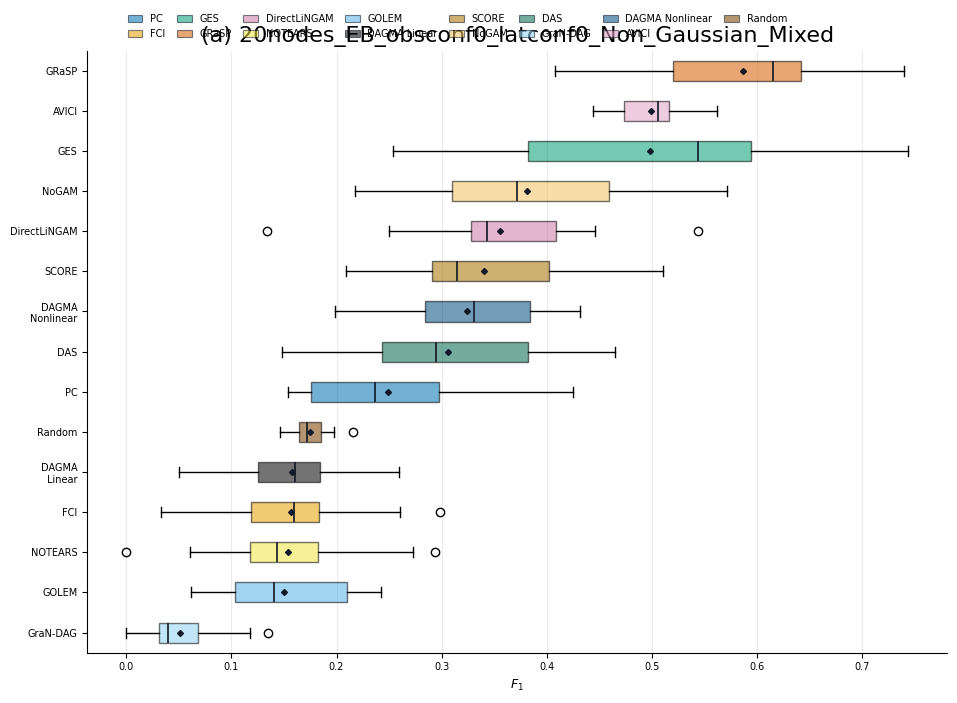

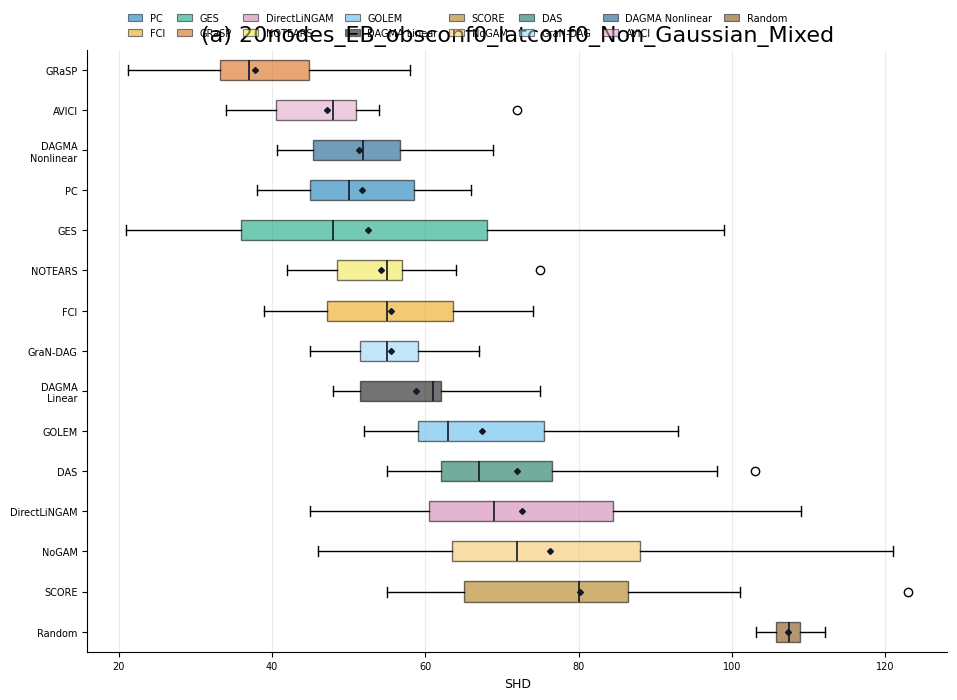

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.160714
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.000000
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.170213
9,19,GraNDAG,0.000000


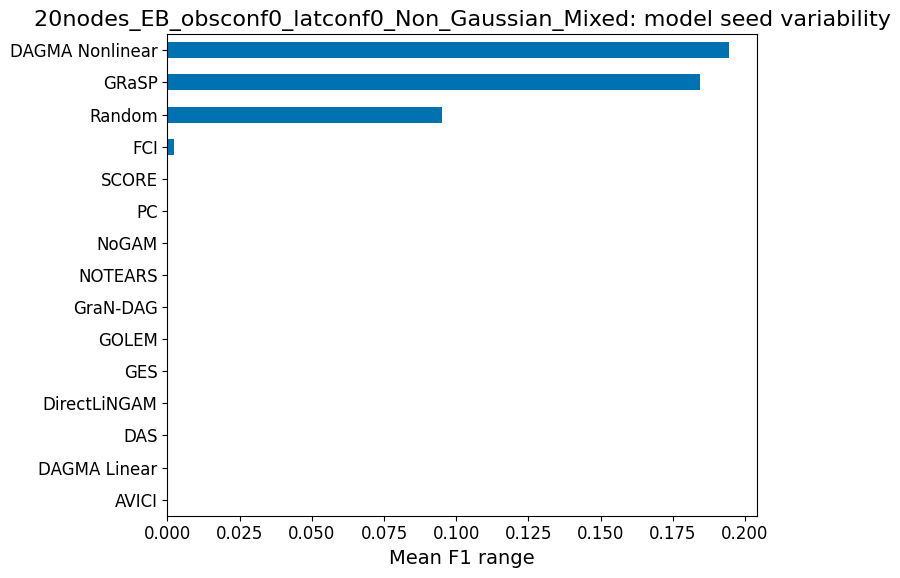

,model_seed,model,f1_range
0,0,AVICI,0.117353
1,0,DAGMA_Linear,0.209740
2,0,DAGMA_Nonlinear,0.285747
3,0,DAS,0.316968
4,0,DirectLiNGAM,0.409713
5,0,FCI,0.265174
6,0,GES,0.490218
7,0,GOLEM,0.180569
8,0,GRaSP,0.258382
9,0,GraNDAG,0.135135


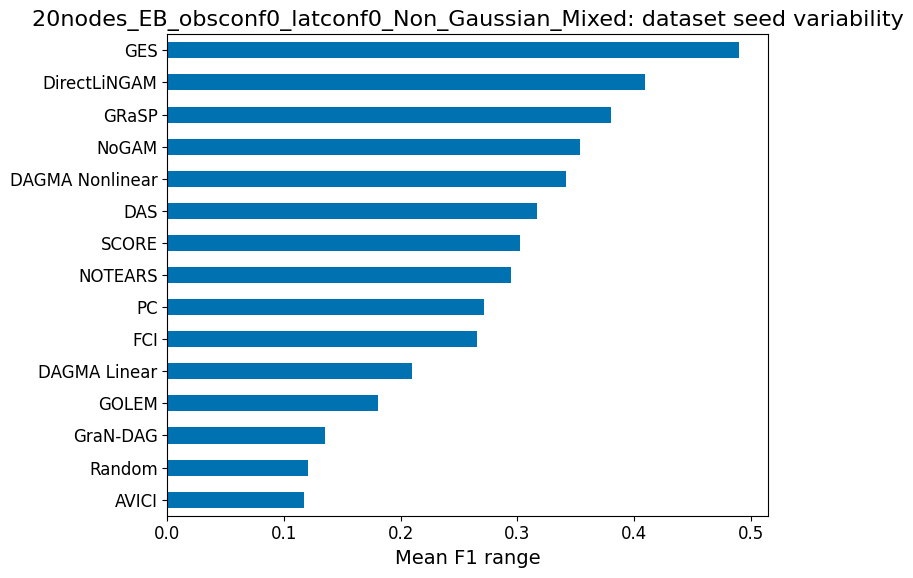

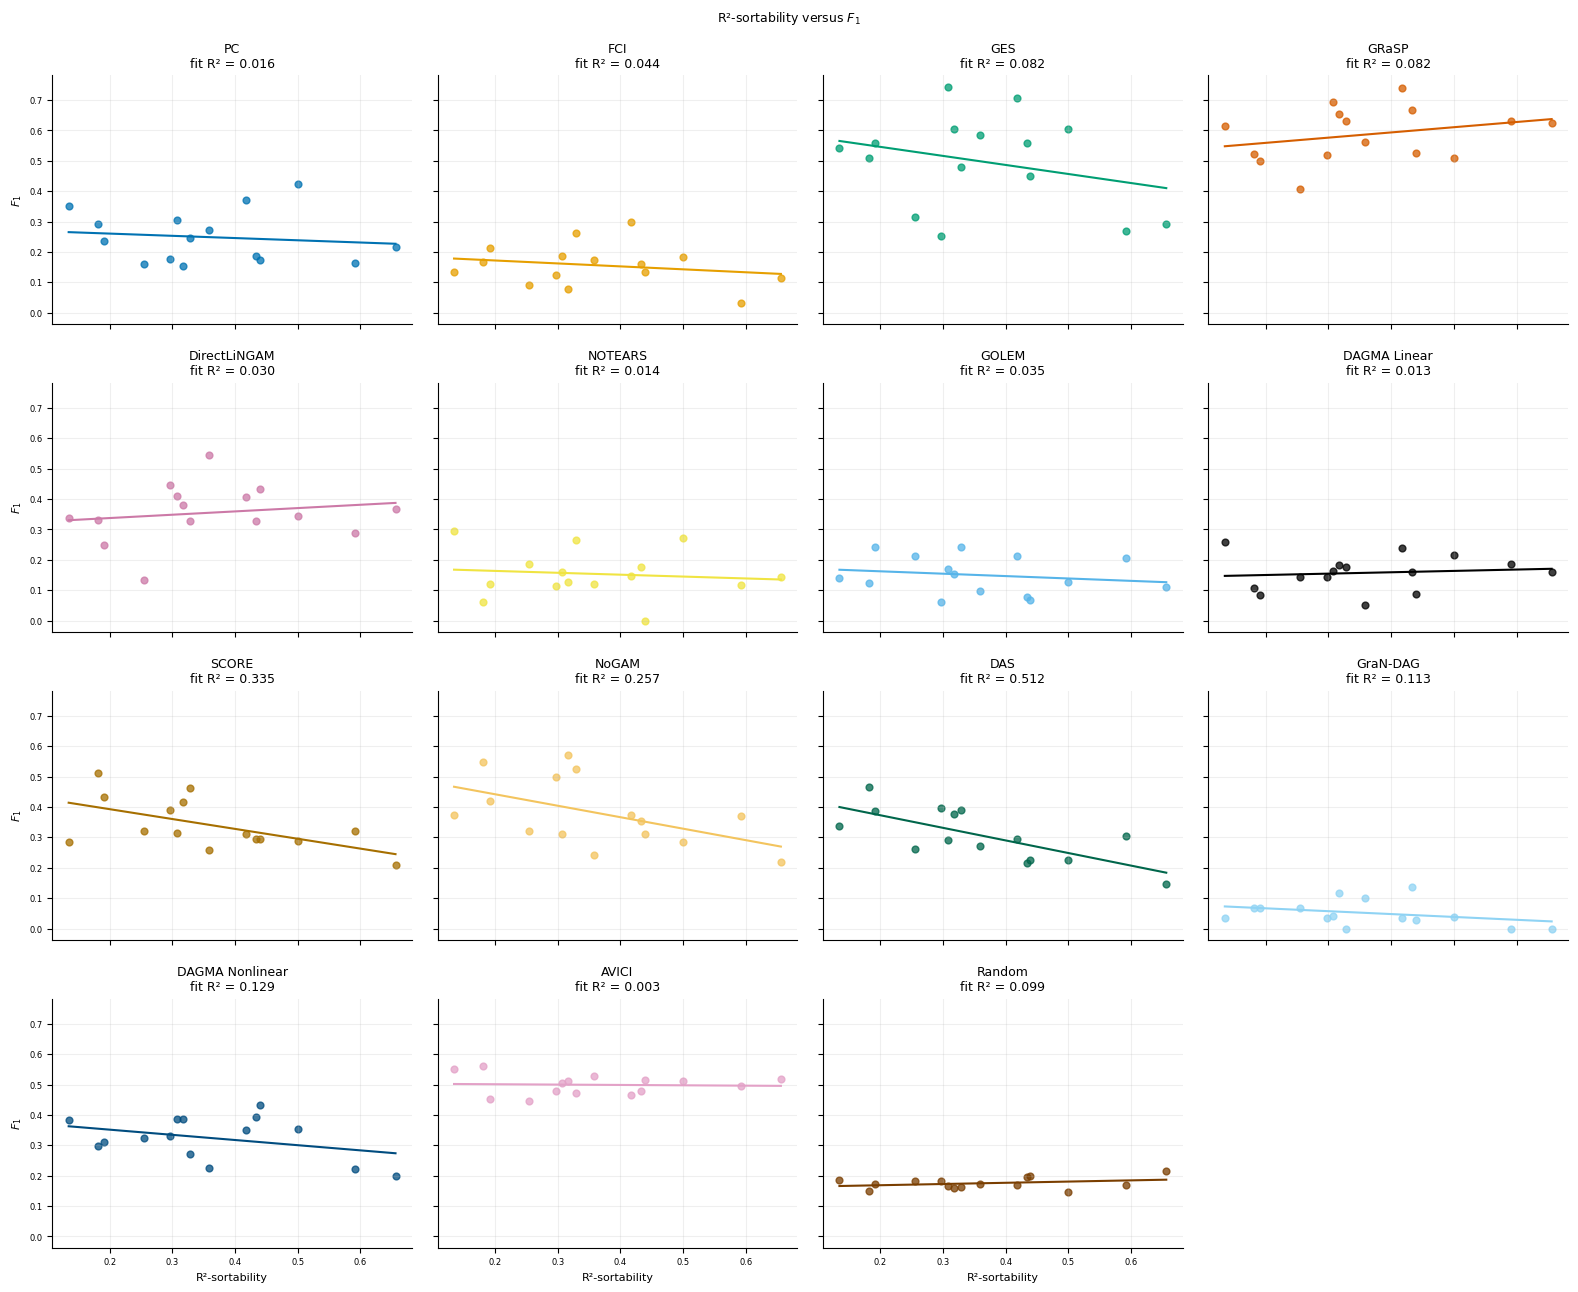

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,0.495413,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,0.187500,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,0.220708,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,0.305344,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,0.287582,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,0.033333,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,0.267606,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,0.207547,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,0.629787,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,0.000000,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.494340,0.358491,265,131,0,95,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.742015,0.656020,407,302,0,267,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.679688,0.433594,256,174,0,111,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.317992,0.297071,239,76,0,71,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.521246,0.328612,353,184,0,116,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.313589,0.181185,287,90,0,52,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.374517,0.254826,259,97,0,66,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.703448,0.317241,145,102,0,46,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.492228,0.134715,193,95,0,26,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,-0.051065,0.002608,-0.011787,0.503293,0.856578,0.010714,0.969770
1,DAGMA_Linear,15,0.114337,0.013073,0.044878,0.141203,0.684932,0.157143,0.575953
2,DAGMA_Nonlinear,15,-0.358543,0.128553,-0.170425,0.385503,0.189415,-0.121429,0.666401
3,DAS,15,-0.715199,0.511510,-0.414527,0.455717,0.002724,-0.667857,0.006510
4,DirectLiNGAM,15,0.172547,0.029772,0.109260,0.315789,0.538597,0.178571,0.524284
5,FCI,15,-0.210287,0.044221,-0.096991,0.191370,0.451898,-0.117857,0.675712
6,GES,15,-0.285728,0.081640,-0.297796,0.605511,0.301912,-0.060714,0.829812
7,GOLEM,15,-0.188027,0.035354,-0.078643,0.178063,0.502172,-0.232143,0.405099
8,GRaSP,15,0.286859,0.082288,0.171597,0.524821,0.299918,0.307143,0.265473
9,GraNDAG,15,-0.336338,0.113123,-0.094524,0.085407,0.220301,-0.412189,0.126828


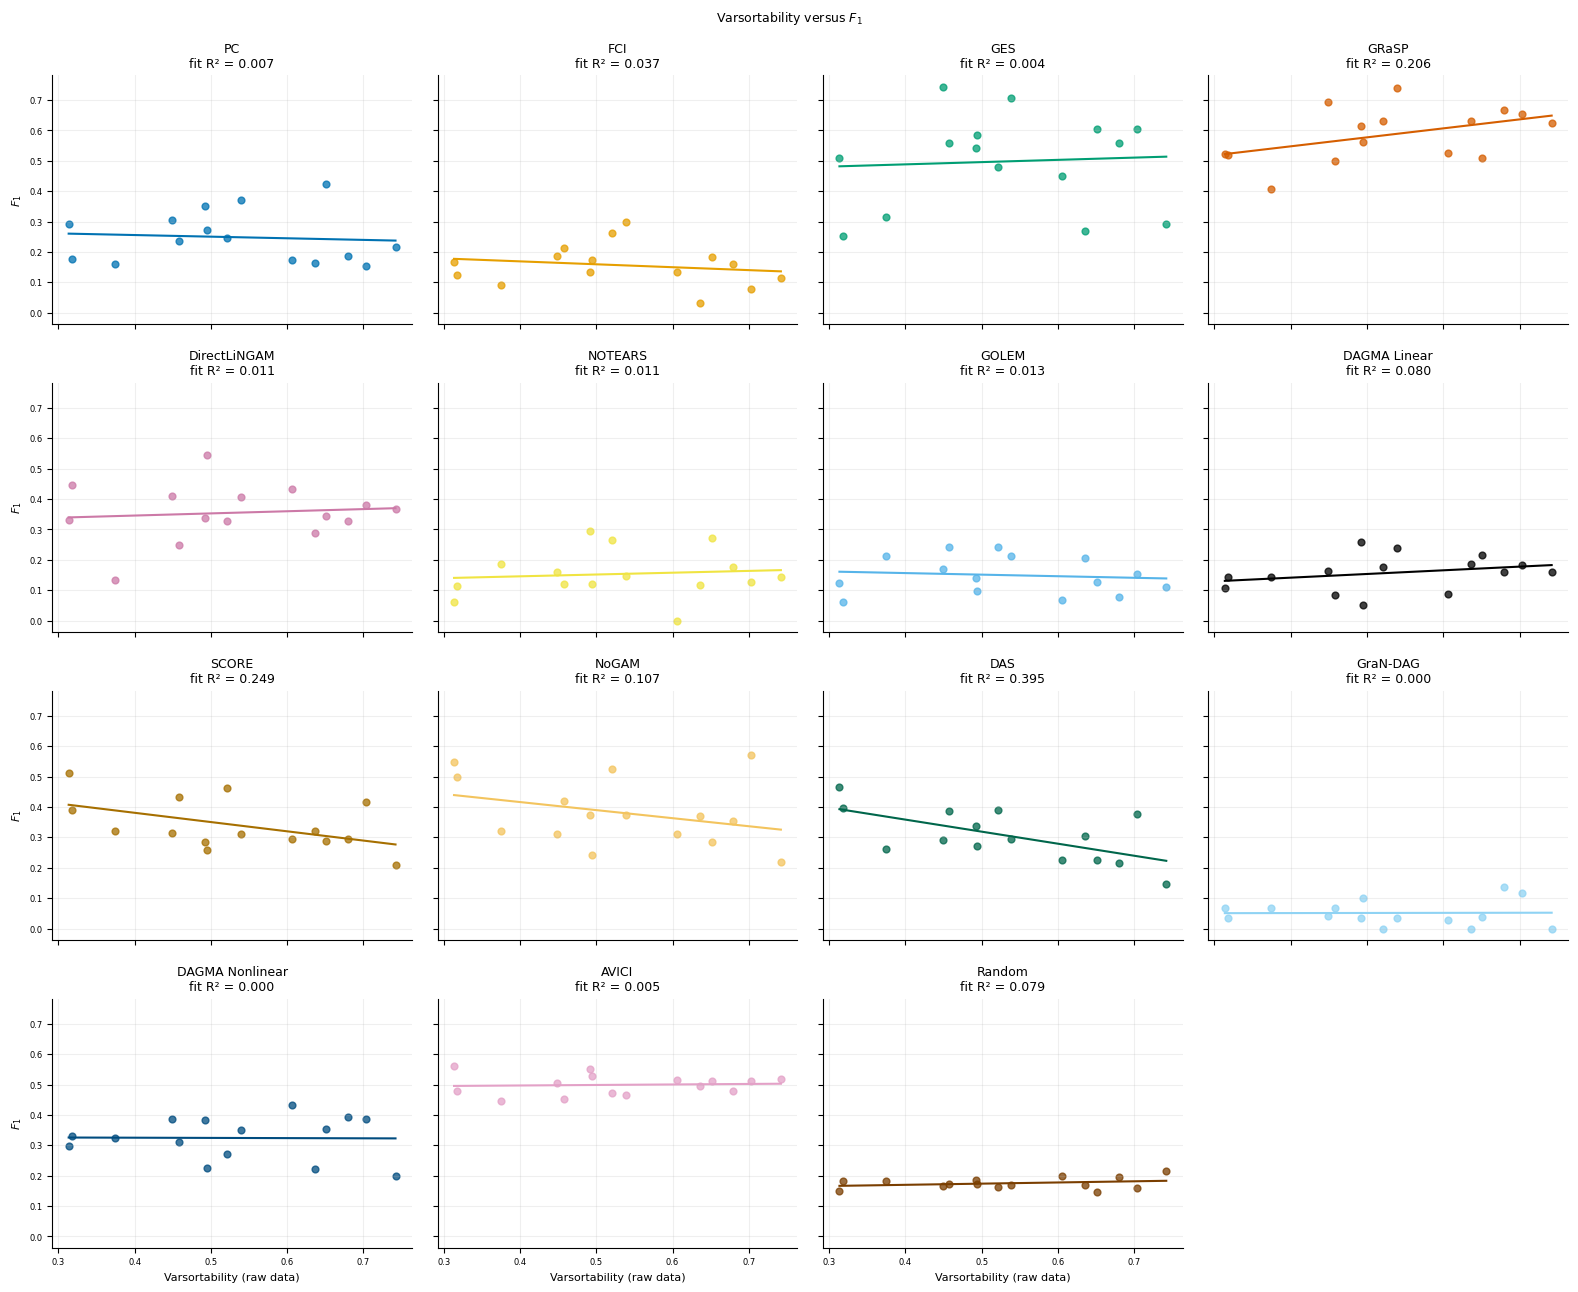

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,0.495413,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,0.187500,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,0.220708,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,0.305344,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,0.287582,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,0.033333,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,0.267606,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,0.207547,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,0.629787,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,0.000000,5,20,EB,0,0,Non_Gaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.636054,0.591837,294,187,0,174,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.494340,0.358491,265,131,0,95,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.742015,0.656020,407,302,0,267,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.679688,0.433594,256,174,0,111,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.317992,0.297071,239,76,0,71,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.521246,0.328612,353,184,0,116,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.313589,0.181185,287,90,0,52,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.374517,0.254826,259,97,0,66,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.703448,0.317241,145,102,0,46,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.492228,0.134715,193,95,0,26,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.067288,0.004528,0.016907,0.490050,0.811675,0.092857,0.742045
1,DAGMA_Linear,15,0.283279,0.080247,0.121034,0.093017,0.306256,0.364286,0.181910
2,DAGMA_Nonlinear,15,-0.012905,0.000167,-0.006677,0.327595,0.963592,0.110714,0.694463
3,DAS,15,-0.628460,0.394962,-0.396503,0.517101,0.012099,-0.592857,0.019846
4,DirectLiNGAM,15,0.102702,0.010548,0.070790,0.317542,0.715694,0.042857,0.879460
5,FCI,15,-0.191603,0.036712,-0.096197,0.207554,0.493925,-0.217857,0.435393
6,GES,15,0.065337,0.004269,0.074126,0.458696,0.817049,0.128571,0.647916
7,GOLEM,15,-0.113493,0.012881,-0.051671,0.177183,0.687148,-0.121429,0.666401
8,GRaSP,15,0.453914,0.206038,0.295568,0.429510,0.089213,0.428571,0.110960
9,GraNDAG,15,0.011186,0.000125,0.003422,0.049499,0.968440,-0.136202,0.628379


In [3]:
for study, frame in [("tuned", complete)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,r2_sortability,15,-0.150000,0.593630,estimated,1.000000
1,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.110714,0.694463,estimated,1.000000
2,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,-0.610714,0.015593,estimated,0.202707
3,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,r2_sortability,15,-0.707143,0.003195,estimated,0.044737
4,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,r2_sortability,15,0.060714,0.829812,estimated,1.000000
5,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,r2_sortability,15,-0.167857,0.549856,estimated,1.000000
6,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,r2_sortability,15,-0.064286,0.819948,estimated,1.000000
7,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,r2_sortability,15,0.121429,0.666401,estimated,1.000000
8,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,r2_sortability,15,0.307143,0.265473,estimated,1.000000
9,tuned,tuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,r2_sortability,15,-0.135714,0.629620,estimated,1.000000
